# 02 — Stylized Facts & Distributional Diagnostics

**Tail Risk Adequacy — Stress-Testing Risk Metrics Across Distributional Assumptions and Market Regimes**
High_Magus_of_Risk

---

## Purpose

Before fitting any risk model, we establish three pieces of evidence that motivate the engine choices in notebook 03:

1. **Distributional shape** — do portfolio returns deviate from Gaussian, and does a Student-t with low ν fit the empirical tails better? *(QQ plots against Gaussian and t at ν ∈ {4, 6, 10}.)*
2. **Serial dependence** — is there autocorrelation in returns (motivating a mean model) and in *squared* returns (motivating a volatility model)? *(Ljung-Box on r and r²; Engle's ARCH-LM.)*
3. **Stress regimes** — fix the set of named crisis windows used throughout the project so every later notebook reads from a single source of truth. *(Saved to `data/stress_windows.json`.)*

These results feed directly into the Phase 1 spec: 1-day-ahead VaR/ES at 99%, rolling 3-year window, two engine families (Gaussian and Student-t with ν ∈ {4, 6, 10}).


---
## 1  Environment Setup

In [11]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

---
## 2  Load Processed Returns

We load the daily return series produced in notebook 01. Focus is on the **FO-portfolio** series — the asset-level series are kept for cross-reference but the risk engines in notebook 03 operate on portfolio returns directly (per the locked design choice: univariate analysis of each portfolio).

In [12]:
returns = pd.read_csv('data/returns.csv', index_col=0, parse_dates=True)
print(f'Loaded {returns.shape[0]:,} observations  |  {returns.index.min().date()} -> {returns.index.max().date()}')
print(f'Columns: {list(returns.columns)}')

# The single diversified family-office portfolio analysed throughout the project
PORTFOLIOS = ['Port_FO']
PORTFOLIO_LABELS = {'Port_FO': 'Family-Office Portfolio (40/25/15/10/10)'}

returns[PORTFOLIOS].head()

Loaded 7,485 observations  |  1996-05-14 -> 2026-04-01
Columns: ['SP500_ret', 'VBMFX_ret', 'REIT_ret', 'GLD_ret', 'Cash_ret', 'SP500_log', 'VBMFX_log', 'Port_FO']


,Port_FO
Date,
1996-05-14,0.004400
1996-05-15,0.000849
1996-05-16,0.000007
1996-05-17,0.004147
1996-05-20,0.002196


---
## 3  Distributional Diagnostics

### 3.1  Recap: Moments and Jarque-Bera

We re-state the headline distributional facts for the FO portfolio. The Jarque-Bera test combines skewness and excess kurtosis into a single $\chi^2_2$ statistic under the null of normality.

In [13]:
def moment_table(df, cols, annualize=252):
    rows = []
    for c in cols:
        s = df[c].dropna()
        jb_stat, jb_p = stats.jarque_bera(s)
        rows.append({
            'Series'        : PORTFOLIO_LABELS.get(c, c),
            'N'             : len(s),
            'Mean (daily)'  : s.mean(),
            'Std (daily)'   : s.std(),
            'Ann. Mean'     : s.mean() * annualize,
            'Ann. Std'      : s.std() * np.sqrt(annualize),
            'Skewness'      : s.skew(),
            'Exc. Kurtosis' : s.kurtosis(),
            'JB Stat'       : jb_stat,
            'JB p-value'    : jb_p,
        })
    return pd.DataFrame(rows).set_index('Series')

display(moment_table(returns, PORTFOLIOS).round(6))

,N,Mean (daily),Std (daily),Ann. Mean,Ann. Std,Skewness,Exc. Kurtosis,JB Stat,JB p-value
Series,,,,,,,,,
Family-Office Portfolio (40/25/15/10/10),7485,0.000317,0.006885,0.079895,0.1093,-0.350164,9.334523,27286.654621,0.0


### 3.2  QQ Plots — Gaussian vs Student-t at $\nu \in \{4, 6, 10\}$

We compare each portfolio's standardized empirical quantiles against the theoretical quantiles of four reference distributions. For each distribution, theoretical quantiles are rescaled to **unit variance**, so the 45° line indicates perfect fit.

For Student-t with $\nu$ degrees of freedom, $\mathrm{Var}(T) = \nu/(\nu-2)$, so quantiles are multiplied by $\sqrt{(\nu-2)/\nu}$ to standardize.

Two figures: the full-range comparison, then a **lower-tail zoom** (theoretical quantile $< -1.5$) — this is the region that matters for VaR/ES at the 99% level.

**ν = 4 — conservative stress floor**
At ν = 4, variance just barely exists (requires ν > 2) and kurtosis is infinite (requires ν > 4). This is the most extreme-tailed t-distribution that remains a valid risk model. **It deliberately overstates tail heaviness relative to your data**, making it the worst-case stress comparator. **If VaR/ES under ν=4 still produces exceptions during crisis periods, it flags model risk regardless of distribution**.

**ν = 6 — empirical and literature benchmark**
This is the most cited value in the academic and practitioner literature:

- Bollerslev (1987) introduced the GARCH-t model using ν ≈ 6–8 for daily equity returns.
- McNeil, Frey & Embrechts Quantitative Risk Management (2005, 2015) use ν ∈ {4, 6} as the standard illustration range. 
- The implied excess kurtosis of 3.0 is the commonly quoted "stylized fact" for daily equity index returns — even though your specific portfolios run higher, ν=6 is the reference point against which heavier and lighter tails are judged.

**ν = 10 — upper bound / transition to Gaussian**
At ν = 10 the distribution is only moderately heavy-tailed (excess kurtosis = 1.0), providing a bridge between the fat-tail specifications and Gaussian. Including it lets you show the gradient: does the extra tail mass in ν=4 and ν=6 actually change VaR/ES materially, or does even ν=10 suffice? It makes the comparison grid complete.

In [14]:
def qq_points(returns, dist, **kw):
    """Return (theoretical_q, sample_q) with theoretical scaled to unit variance."""
    z = (returns - returns.mean()) / returns.std()
    n = len(z)
    p = (np.arange(1, n + 1) - 0.5) / n
    sample_q = np.sort(z.values)
    if dist == 'norm':
        theo_q = stats.norm.ppf(p)
    elif dist == 't':
        nu = kw['df']
        scale = np.sqrt((nu - 2) / nu)
        theo_q = stats.t.ppf(p, df=nu) * scale
    return theo_q, sample_q

DIST_PANELS = [
    ('Gaussian',    {'dist': 'norm'},          'steelblue'),
    ('Student-t, ν=10', {'dist': 't', 'df': 10}, '#f4a261'),
    ('Student-t, ν=6',  {'dist': 't', 'df': 6},  '#e76f51'),
    ('Student-t, ν=4',  {'dist': 't', 'df': 4},  '#9d0208'),
]

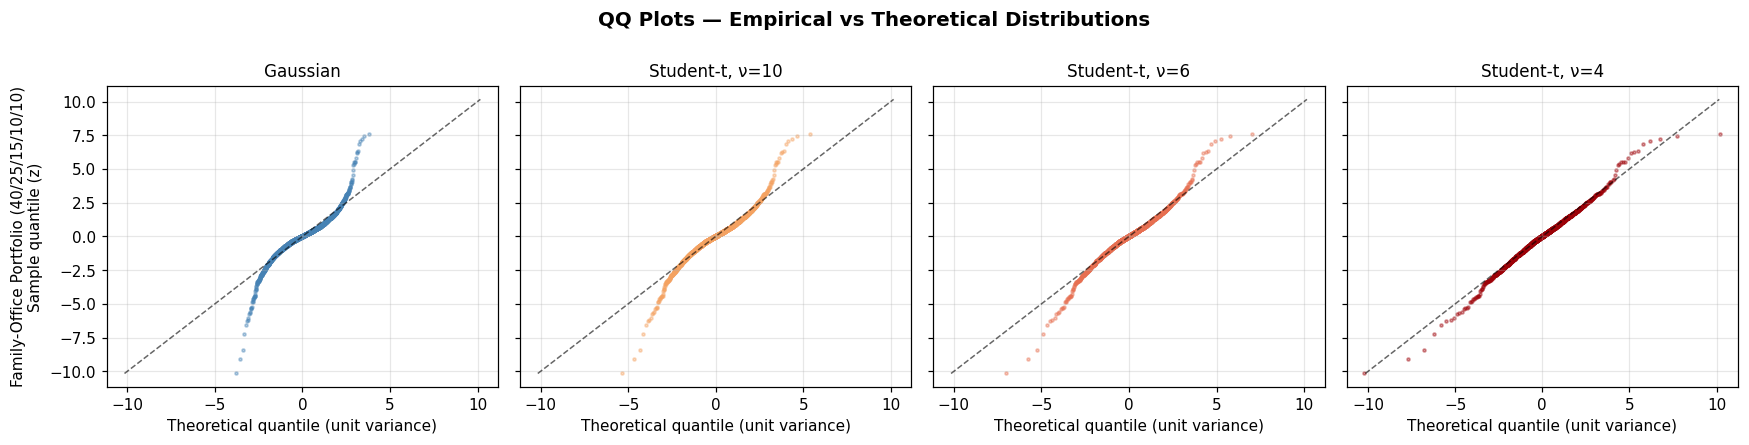

In [15]:
# Full-range QQ plot — the FO portfolio × 4 distributions
fig, axes = plt.subplots(len(PORTFOLIOS), len(DIST_PANELS),
                         figsize=(16, 4 * len(PORTFOLIOS)),
                         sharex='col', sharey='row', squeeze=False)

for i, port in enumerate(PORTFOLIOS):
    s = returns[port].dropna()
    for j, (label, kw, color) in enumerate(DIST_PANELS):
        ax = axes[i, j]
        theo_q, samp_q = qq_points(s, **kw)
        ax.scatter(theo_q, samp_q, s=4, alpha=0.4, color=color)
        lim = max(abs(samp_q.min()), abs(samp_q.max()))
        ax.plot([-lim, lim], [-lim, lim], 'k--', lw=1, alpha=0.6)
        if i == 0:
            ax.set_title(label, fontsize=11)
        if j == 0:
            ax.set_ylabel(f'{PORTFOLIO_LABELS[port]}\nSample quantile (z)', fontsize=10)
        if i == len(PORTFOLIOS) - 1:
            ax.set_xlabel('Theoretical quantile (unit variance)', fontsize=10)

fig.suptitle('QQ Plots — Empirical vs Theoretical Distributions', fontsize=13, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

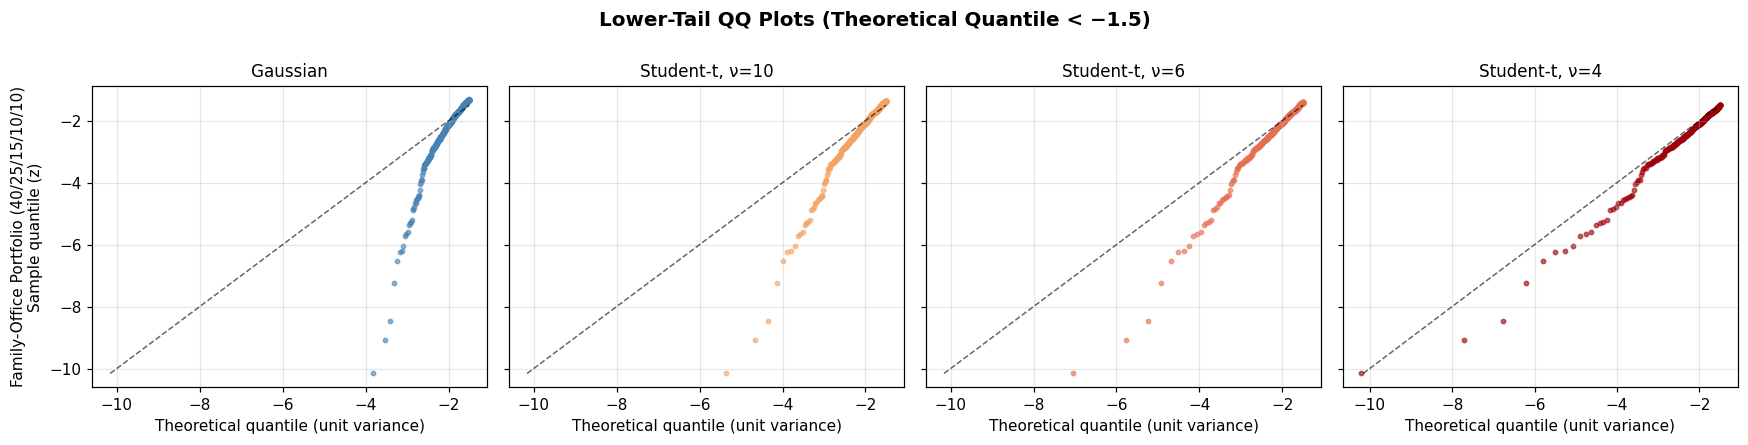

In [16]:
# Lower-tail zoom — theoretical quantile < -1.5
fig, axes = plt.subplots(len(PORTFOLIOS), len(DIST_PANELS),
                         figsize=(16, 4 * len(PORTFOLIOS)),
                         sharex='col', sharey='row', squeeze=False)

for i, port in enumerate(PORTFOLIOS):
    s = returns[port].dropna()
    for j, (label, kw, color) in enumerate(DIST_PANELS):
        ax = axes[i, j]
        theo_q, samp_q = qq_points(s, **kw)
        mask = theo_q < -1.5
        ax.scatter(theo_q[mask], samp_q[mask], s=8, alpha=0.6, color=color)
        lim = abs(samp_q[mask].min())
        ax.plot([-lim, -1.5], [-lim, -1.5], 'k--', lw=1, alpha=0.6)
        if i == 0:
            ax.set_title(label, fontsize=11)
        if j == 0:
            ax.set_ylabel(f'{PORTFOLIO_LABELS[port]}\nSample quantile (z)', fontsize=10)
        if i == len(PORTFOLIOS) - 1:
            ax.set_xlabel('Theoretical quantile (unit variance)', fontsize=10)

fig.suptitle('Lower-Tail QQ Plots (Theoretical Quantile < −1.5)', fontsize=13, fontweight='bold', y=1.00)
plt.tight_layout()
plt.show()

### 3.3  Interpretation

What to look for in the QQ plots:

- **Gaussian (left column)** — sample points should bend **below** the 45° line in the left tail if returns are heavier-tailed than normal. This is the signature of fat tails: extreme realized losses exceed what a normal distribution predicts.
- **Student-t, ν=10** — modestly heavier tails than Gaussian; expect partial correction of the left-tail bend.
- **Student-t, ν=6** — empirically a common fit for daily equity returns; the kurtosis implied by ν=6 is excess kurtosis = 6/(ν−4) = 3.0, which is in the ballpark of what daily equity returns exhibit.
- **Student-t, ν=4** — variance exists but kurtosis is infinite; this is an extreme-tail stress comparator. If the sample tail still bends below the 45° line for ν=4, it suggests an even heavier tail (skew-t or jump-diffusion territory).

The **lower-tail zoom** is the visual that matters for the project: VaR/ES at 99% live at theoretical quantiles around −2.33 (Gaussian) to −3.7 (t with ν=4). **Whichever panel hugs the 45° line in this zone is the distribution whose VaR/ES will *not* systematically understate tail loss**.

---
## 4  Time-Series Diagnostics

The QQ plots establish that the **marginal** distribution is non-Gaussian. We now check whether the *sequence* of returns is iid — relevant because the Phase 1 engines assume the rolling window is a sample from a stationary distribution.

Two formal tests:

- **Ljung-Box on returns ($r_t$)** — tests $H_0$: no autocorrelation in returns at lags $1, \ldots, h$. For daily equity returns, this is typically not rejected at short lags (efficient-market intuition), though there can be weak negative autocorrelation from bid-ask bounce.
- **Ljung-Box on squared returns ($r_t^2$)** — tests for autocorrelation in *volatility*. Strong rejection here is the signature of **volatility clustering**, the stylized fact that motivates GARCH-family models in Phase 2.
- **Engle's ARCH-LM** — a regression-based test for ARCH effects of order $q$; complements the LB on $r^2$.

### 4.1  Ljung-Box on Returns

In [17]:
def lb_table(df, cols, lags=(5, 10, 20), squared=False):
    out = []
    for c in cols:
        s = df[c].dropna()
        x = s ** 2 if squared else s
        lb = acorr_ljungbox(x, lags=list(lags), return_df=True)
        row = {'Series': PORTFOLIO_LABELS.get(c, c)}
        for L in lags:
            row[f'LB(lag {L}) stat']    = lb.loc[L, 'lb_stat']
            row[f'LB(lag {L}) p-value'] = lb.loc[L, 'lb_pvalue']
        out.append(row)
    return pd.DataFrame(out).set_index('Series')

print('Ljung-Box test — H0: no autocorrelation in returns r_t at lags 1..h')
display(lb_table(returns, PORTFOLIOS, squared=False).round(6))

Ljung-Box test — H0: no autocorrelation in returns r_t at lags 1..h


,LB(lag 5) stat,LB(lag 5) p-value,LB(lag 10) stat,LB(lag 10) p-value,LB(lag 20) stat,LB(lag 20) p-value
Series,,,,,,
Family-Office Portfolio (40/25/15/10/10),24.475653,0.000176,49.086936,0.0,85.854052,0.0


### 4.2  Ljung-Box on Squared Returns — Volatility Clustering

In [18]:
print('Ljung-Box test on r²_t — H0: no autocorrelation in squared returns (no vol clustering)')
display(lb_table(returns, PORTFOLIOS, squared=True).round(6))

Ljung-Box test on r²_t — H0: no autocorrelation in squared returns (no vol clustering)


,LB(lag 5) stat,LB(lag 5) p-value,LB(lag 10) stat,LB(lag 10) p-value,LB(lag 20) stat,LB(lag 20) p-value
Series,,,,,,
Family-Office Portfolio (40/25/15/10/10),3614.039547,0.0,6388.455047,0.0,9640.591419,0.0


### 4.3  Engle's ARCH-LM Test

Regresses $r_t^2$ on its own lags $r_{t-1}^2, \ldots, r_{t-q}^2$ and tests $H_0$: all coefficients zero (no ARCH effects). Reported at $q = 5$.

In [19]:
def arch_lm_table(df, cols, nlags=5):
    out = []
    for c in cols:
        s = df[c].dropna()
        lm, lm_p, f, f_p = het_arch(s, nlags=nlags)
        out.append({
            'Series'        : PORTFOLIO_LABELS.get(c, c),
            'LM Stat'       : lm,
            'LM p-value'    : lm_p,
            'F Stat'        : f,
            'F p-value'     : f_p,
        })
    return pd.DataFrame(out).set_index('Series')

print('Engle ARCH-LM test at lag 5 — H0: no ARCH effects')
display(arch_lm_table(returns, PORTFOLIOS, nlags=5).round(6))

Engle ARCH-LM test at lag 5 — H0: no ARCH effects


,LM Stat,LM p-value,F Stat,F p-value
Series,,,,
Family-Office Portfolio (40/25/15/10/10),1711.396272,0.0,443.468692,0.0


### 4.4  Interpretation

The expected pattern in daily portfolio data:

- **LB on $r_t$**: small-to-moderate test statistics — possibly rejecting at long lags but with no economically meaningful structure. *Implication for Phase 1:* a zero-mean (or rolling-mean) assumption for the VaR/ES engine is defensible.
- **LB on $r_t^2$**: large statistics, p-values $\approx 0$ at every lag. *Implication:* the iid assumption underlying the rolling-window engines is violated in the second moment. This is the well-known **volatility clustering** stylized fact and the motivation for the Phase 2 GARCH/FHS extensions.
- **ARCH-LM**: should confirm the LB-$r^2$ result. Strong rejection.

For Phase 1, we proceed with the rolling Gaussian/Student-t engines *despite* the clustering — the comparison between Phase 1 and Phase 2 (where volatility filtering is added) becomes one of the key findings of the project.

---
## 5  Stress-Window Definitions

We fix four named crisis windows that will be reused **identically** in every downstream notebook. Saving them to `data/stress_windows.json` ensures a single source of truth and makes the stress-period scorecard (notebook 04) trivially reproducible.

| Window           | Start         | End           | Description |
|------------------|---------------|---------------|-------------|
| `DotCom_2000_2003`| 2000-09-01   | 2003-03-31    | Dot-com bust — 2000-2003 equity bear market (slow-motion unwind) |
| `GFC`            | 2008-09-15    | 2009-06-30    | Global Financial Crisis (post-Lehman through trough recovery) |
| `COVID`          | 2020-02-15    | 2020-05-31    | COVID-19 market shock and initial recovery |
| `Rate_Hikes_2022`| 2022-01-01    | 2022-12-31    | 2022 monetary tightening / rate-hike stress year |

In [20]:
import os, json

STRESS_WINDOWS = {
    'DotCom_2000_2003': {'start': '2000-09-01', 'end': '2003-03-31',
                        'description': 'Dot-com bust / 2000-2003 equity bear market'},
    'GFC'            : {'start': '2008-09-15', 'end': '2009-06-30',
                        'description': 'Global Financial Crisis'},
    'COVID'          : {'start': '2020-02-15', 'end': '2020-05-31',
                        'description': 'COVID-19 market shock'},
    'Rate_Hikes_2022': {'start': '2022-01-01', 'end': '2022-12-31',
                        'description': '2022 rate-hike regime'},
}

# Count observations falling in each window for each portfolio
def window_counts(returns, windows, cols):
    out = []
    for name, w in windows.items():
        mask = (returns.index >= w['start']) & (returns.index <= w['end'])
        row = {'Window': name, 'Start': w['start'], 'End': w['end'],
               'Trading days': mask.sum()}
        for c in cols:
            row[f'{PORTFOLIO_LABELS[c]} mean ret'] = returns.loc[mask, c].mean()
            row[f'{PORTFOLIO_LABELS[c]} std']     = returns.loc[mask, c].std()
            row[f'{PORTFOLIO_LABELS[c]} min']     = returns.loc[mask, c].min()
        out.append(row)
    return pd.DataFrame(out).set_index('Window')

display(window_counts(returns, STRESS_WINDOWS, PORTFOLIOS).round(6))

# Persist
os.makedirs('data', exist_ok=True)
with open('data/stress_windows.json', 'w') as f:
    json.dump(STRESS_WINDOWS, f, indent=2)
print('\nSaved → data/stress_windows.json')

,Start,End,Trading days,Family-Office Portfolio (40/25/15/10/10) mean ret,Family-Office Portfolio (40/25/15/10/10) std,Family-Office Portfolio (40/25/15/10/10) min
Window,,,,,,
DotCom_2000_2003,2000-09-01,2003-03-31,637,-0.000138,0.006538,-0.019734
GFC,2008-09-15,2009-06-30,200,-0.000482,0.019300,-0.062208
COVID,2020-02-15,2020-05-31,72,-0.000801,0.021011,-0.069627
Rate_Hikes_2022,2022-01-01,2022-12-31,251,-0.000613,0.009636,-0.030334



Saved → data/stress_windows.json


---
## 6  Summary & Next Steps

### What we established

- **Marginal distribution is non-Gaussian**: Jarque-Bera rejects normality decisively for the FO portfolio; QQ plots show the characteristic left-tail bend below the 45° line under the Gaussian comparator. Among Student-t comparators, $\nu \in \{6, 10\}$ visually improve tail fit; $\nu = 4$ is the heavy-tail stress benchmark.
- **Returns show weak (or no) autocorrelation in levels** but **strong autocorrelation in squared returns** — the volatility-clustering signature. This is why a *rolling-window* Phase 1 engine is appropriate (it tracks the level of volatility over time) and why a *filtered* Phase 2 engine (GARCH/FHS) is the natural extension.
- **Stress windows are now fixed** and saved to `data/stress_windows.json`. Every downstream notebook reads from this file.

### Locked design parameters (for notebook 03)

| Parameter           | Value                                              |
|---------------------|----------------------------------------------------|
| Forecast horizon    | 1 day                                              |
| Calibration window  | Rolling 4 years (≈ 1000 trading days)             |
| Confidence level    | **99%** (97.5% reserved as future robustness)      |
| Engines             | Gaussian + Student-t at $\nu \in \{4, 6, 10\}$     |
| Metrics             | VaR, ES, plus rolling volatility baseline          |
| Portfolios          | `Port_FO`                   |
| Backtest            | Exception rate, mean loss \| exception, mean $L - \mathrm{ES}$ \| exception, overall + per stress window |

### Next notebook — `03_Risk_Engines_Phase1.ipynb`

1. Build the rolling backtest timeline ($t_0 = 1{,}250$).
2. Implement the analytic Gaussian VaR/ES engine (vectorized on `pandas.rolling`).
3. Implement the closed-form Student-t VaR/ES engine for each $\nu$.
4. Run the four engines (Gaussian, t-4, t-6, t-10) on the FO portfolio and persist `(VaR_t, ES_t)` per (engine × portfolio).
5. Backtest each combination overall and on the four stress windows.
6. Produce the realized-loss vs VaR-lines time-series chart per portfolio.

Anything beyond that — block bootstrap, FHS-GARCH, drawdown layer, Kupiec/Christoffersen formal tests, 10-day horizon — is reserved as Phase 2 robustness.